# P17: can the guide tell when it is not sure?

P10 found that 29 of the final model's 80 validation mistakes were made with a confidence above 0.8, and that the true genre
is its first or second choice for 95% of the paintings. A guide that tells a visitor the wrong story with confidence is worse
than one that says "this is a portrait or a religious painting". Two questions:

1. **Calibration.** When the model says 0.9, is it right 90% of the time? Measured with the **expected calibration error**
   (ECE: the paintings are grouped by confidence in 15 bins of equal width; in each bin, the gap between the mean confidence
   and the accuracy, weighted by the share of paintings in the bin). The usual repair is **temperature scaling**: divide the
   scores by one number T before the softmax, chosen to minimise the loss on validation. It never changes the predicted genre,
   only how sure the model claims to be.
2. **Abstention.** Below a confidence threshold, the guide gives its two best genres instead of one.

**The rules, fixed before any result** (a scratch run, unsaved, checked the code):

- The final model (ADR 0012) is not changed or retrained. T is fitted on validation; the ECE on validation after scaling is
  measured by **2-fold cross-fitting** (T fitted on one half of the validation paintings, measured on the other, and the
  other way round), so it is not measured on the paintings that chose T.
- **The threshold** is the lowest confidence (after scaling) at which the paintings the guide answers alone are right at
  least **95%** of the time on validation. Below it, the guide shows its two best genres.
- **Museum B once:** the ECE before and after scaling, and the share answered alone, their accuracy and the top-2 accuracy of
  the others, with T and the threshold chosen on validation. The predictions themselves were already scored (86.0%,
  ADR 0012); this only measures confidence. T and the threshold go to `results/confidence.json`, for the demo.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import (
    PERTURBATIONS, RESULTS_DIR, final_model, perturb, predict_logits, split_images)

model = final_model()
val_images, val_labels = split_images("val")
val_logits = predict_logits(model, val_images)
print(f"final model, validation accuracy {(val_logits.argmax(1) == val_labels).float().mean():.1%} (ADR 0012: 83.3%)")


def ece(probs, labels, bins=15):
    """Expected calibration error: in bins of equal width of the top confidence, the gap |accuracy - mean confidence|,
    weighted by the share of paintings in each bin."""
    confidence, predicted = probs.max(dim=1)
    correct = (predicted == labels).float()
    edges = torch.linspace(0, 1, bins + 1)
    error = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        inside = (confidence > low) & (confidence <= high)
        if inside.any():
            error += inside.float().mean() * (correct[inside].mean() - confidence[inside].mean()).abs()
    return float(error)


def fit_temperature(logits, labels):
    """The temperature T that minimises the cross-entropy of softmax(logits / T) on these paintings (LBFGS on log T)."""
    log_t = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    loss_fn = torch.nn.CrossEntropyLoss()

    def closure():
        optimizer.zero_grad()
        loss = loss_fn(logits / log_t.exp(), labels)
        loss.backward()
        return loss

    optimizer.step(closure)
    return log_t.exp().item()


def nll(logits, labels, t=1.0):
    return torch.nn.functional.cross_entropy(logits / t, labels).item()

final model, validation accuracy 83.3% (ADR 0012: 83.3%)


## 1. Calibration and temperature scaling

In [2]:
before = ece(val_logits.softmax(1), val_labels)
order = torch.randperm(len(val_labels), generator=torch.Generator().manual_seed(0))
halves = [order[: len(order) // 2], order[len(order) // 2:]]
crossfit_ece, crossfit_t = [], []
for fit_half, eval_half in [(0, 1), (1, 0)]:
    t = fit_temperature(val_logits[halves[fit_half]], val_labels[halves[fit_half]])
    crossfit_t.append(t)
    crossfit_ece.append(ece((val_logits[halves[eval_half]] / t).softmax(1), val_labels[halves[eval_half]]))
T = fit_temperature(val_logits, val_labels)

mistakes = val_logits.argmax(1) != val_labels
confident_before = (val_logits.softmax(1).max(1).values[mistakes] > 0.8).sum().item()
confident_after = ((val_logits / T).softmax(1).max(1).values[mistakes] > 0.8).sum().item()
print(f"temperature fitted on all of validation: T = {T:.2f} (on each half: {crossfit_t[0]:.2f} and {crossfit_t[1]:.2f})")
print(f"validation ECE: before {before:.3f} | after, cross-fitted {np.mean(crossfit_ece):.3f} (halves {crossfit_ece[0]:.3f}, {crossfit_ece[1]:.3f})")
print(f"validation loss: before {nll(val_logits, val_labels):.3f}, after {nll(val_logits, val_labels, T):.3f}")
print(f"mistakes made with a confidence above 0.8: {confident_before} of {mistakes.sum().item()} before, {confident_after} after")

temperature fitted on all of validation: T = 1.23 (on each half: 1.27 and 1.18)
validation ECE: before 0.061 | after, cross-fitted 0.068 (halves 0.069, 0.067)
validation loss: before 0.475, after 0.463
mistakes made with a confidence above 0.8: 29 of 80 before, 22 after


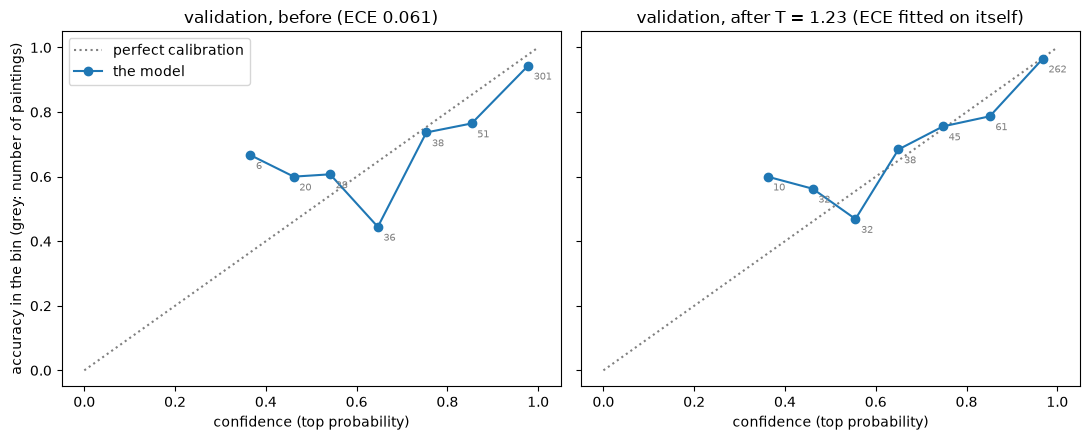

In [3]:
def reliability(ax, probs, labels, title, bins=10):
    confidence, predicted = probs.max(dim=1)
    correct = (predicted == labels).float()
    edges = np.linspace(0, 1, bins + 1)
    centres, accuracies, counts = [], [], []
    for low, high in zip(edges[:-1], edges[1:]):
        inside = (confidence > low) & (confidence <= high)
        if inside.sum() > 0:
            centres.append(confidence[inside].mean().item())
            accuracies.append(correct[inside].mean().item())
            counts.append(inside.sum().item())
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect calibration")
    ax.plot(centres, accuracies, marker="o", color="tab:blue", label="the model")
    for x, y, n in zip(centres, accuracies, counts):
        ax.annotate(str(n), (x, y), textcoords="offset points", xytext=(4, -10), fontsize=7, color="grey")
    ax.set_xlabel("confidence (top probability)")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
reliability(axes[0], val_logits.softmax(1), val_labels, f"validation, before (ECE {before:.3f})")
reliability(axes[1], (val_logits / T).softmax(1), val_labels, f"validation, after T = {T:.2f} (ECE fitted on itself)")
axes[0].set_ylabel("accuracy in the bin (grey: number of paintings)")
axes[0].legend()
plt.tight_layout()
plt.show()

**What we see.**

- **The model is already fairly well calibrated:** ECE 0.061 on validation. Its 301 most confident paintings (confidence about 0.98) are right 94% of the time; the middle bins hold 20 to 50 paintings each and swing around the diagonal.
- **T = 1.23** (1.27 and 1.18 on the two halves): above 1, so the model is slightly over-confident, and scaling softens it. The validation loss drops from 0.475 to 0.463, and the mistakes made with a confidence above 0.8 go from 29 to 22 out of 80.
- **But the cross-fitted ECE does not improve:** 0.068 against 0.061 before. With 240 paintings per half, the ECE moves by about as much as temperature scaling can fix. On validation, temperature scaling is a small, harmless change, not a measurable repair.

## 2. Answering alone, or showing two genres

For every threshold, the share of paintings the guide answers alone (coverage) and how often those answers are right. The
threshold is the lowest one that keeps them right at least 95% of the time (rule above).

threshold chosen on validation: 0.86
{'answered alone': 0.6, 'accuracy answered alone': 0.951, 'top-2 accuracy of the others': 0.896, 'right genre shown (1 or 2 genres)': 0.929}


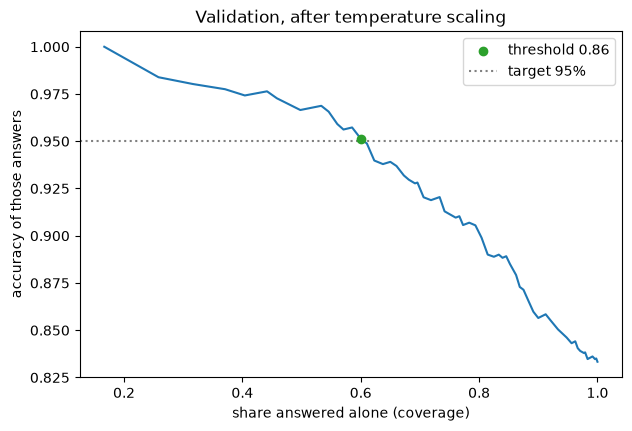

In [4]:
TARGET = 0.95
val_probs = (val_logits / T).softmax(1)
confidence, predicted = val_probs.max(1)
correct = predicted == val_labels
top2 = (val_probs.topk(2, dim=1).indices == val_labels[:, None]).any(dim=1)

grid = np.round(np.arange(0.20, 1.00, 0.01), 2)
curve = pd.DataFrame([{"threshold": t, "coverage": (confidence >= t).float().mean().item(),
                       "accuracy answered": correct[confidence >= t].float().mean().item() if (confidence >= t).any() else np.nan}
                      for t in grid])
THRESHOLD = float(curve.loc[curve["accuracy answered"] >= TARGET, "threshold"].min())


def policy(confidence, correct, top2, threshold):
    alone = confidence >= threshold
    return {"answered alone": alone.float().mean().item(), "accuracy answered alone": correct[alone].float().mean().item(),
            "top-2 accuracy of the others": top2[~alone].float().mean().item() if (~alone).any() else np.nan,
            "right genre shown (1 or 2 genres)": torch.where(alone, correct, top2).float().mean().item()}


val_policy = policy(confidence, correct, top2, THRESHOLD)
print(f"threshold chosen on validation: {THRESHOLD:.2f}")
print({k: round(v, 3) for k, v in val_policy.items()})

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(curve["coverage"], curve["accuracy answered"], color="tab:blue")
ax.scatter(val_policy["answered alone"], val_policy["accuracy answered alone"], color="tab:green", zorder=3,
           label=f"threshold {THRESHOLD:.2f}")
ax.axhline(TARGET, color="grey", linestyle=":", label="target 95%")
ax.set_xlabel("share answered alone (coverage)")
ax.set_ylabel("accuracy of those answers")
ax.set_title("Validation, after temperature scaling")
ax.legend()
plt.show()

### Does the guide notice a bad photo?

The same threshold on the validation paintings at the strong level of the three perturbations that hurt most in P15
(blur, JPEG, distance). If the guide knows it is unsure, it answers alone less often, and what it still answers alone stays
mostly right.

In [5]:
rows = {"clean": val_policy}
for kind in ["blur", "jpeg", "far"]:
    rng = np.random.default_rng(0)  # the same photos as P15
    logits = predict_logits(model, [perturb(im, kind, PERTURBATIONS[kind][-1], rng) for im in val_images])
    probs = (logits / T).softmax(1)
    conf, pred = probs.max(1)
    rows[f"{kind}, strong"] = {**policy(conf, pred == val_labels, (probs.topk(2, dim=1).indices == val_labels[:, None]).any(1),
                                        THRESHOLD), "accuracy (all)": (pred == val_labels).float().mean().item()}
rows["clean"]["accuracy (all)"] = correct.float().mean().item()
pd.DataFrame(rows).T[["accuracy (all)", "answered alone", "accuracy answered alone", "top-2 accuracy of the others",
                      "right genre shown (1 or 2 genres)"]].round(3)

,accuracy (all),answered alone,accuracy answered alone,top-2 accuracy of the others,right genre shown (1 or 2 genres)
clean,0.833,0.600,0.951,0.896,0.929
"blur, strong",0.548,0.179,0.791,0.759,0.765
"jpeg, strong",0.490,0.229,0.782,0.741,0.750
"far, strong",0.631,0.073,0.971,0.784,0.798


**What we see.**

- **The threshold is 0.86.** Above it the guide answers alone for 60% of the validation paintings, right 95.1% of the time. For the other 40% it shows two genres, and the true one is among them 89.6% of the time. Overall, the right genre is on the screen for 92.9% of the paintings, against 83.3% when the guide always gives one answer.
- **On bad photos the guide becomes cautious.** At the strong level it answers alone for only 18% (blur), 23% (JPEG) and 7% (distance) of the paintings, against 60% on clean ones. Its lone answers stay right 79%, 78% and 97% of the time, against overall accuracies of 55%, 49% and 63%.
- **That caution is not enough for blur and JPEG:** about one lone answer in five is wrong, and with two genres the right one is shown for only 75 to 77% of the paintings. The confidence threshold does not replace a check of the photo itself (P15).

## 3. Museum B, once

In [6]:
test_images, test_labels = split_images("test")
test_logits = predict_logits(model, test_images)
test_probs = (test_logits / T).softmax(1)
conf, pred = test_probs.max(1)
test_policy = policy(conf, pred == test_labels, (test_probs.topk(2, dim=1).indices == test_labels[:, None]).any(1), THRESHOLD)
summary_b = {"accuracy": (pred == test_labels).float().mean().item(),
             "ECE before": ece(test_logits.softmax(1), test_labels), "ECE after": ece(test_probs, test_labels),
             "loss before": nll(test_logits, test_labels), "loss after": nll(test_logits, test_labels, T), **test_policy}
print({k: round(v, 3) for k, v in summary_b.items()})

saved = {"temperature": round(T, 4), "threshold": THRESHOLD, "target_accuracy_answered": TARGET,
         "validation": {"ece_before": round(before, 4), "ece_after_crossfitted": round(float(np.mean(crossfit_ece)), 4),
                        **{k: round(v, 4) for k, v in val_policy.items()}},
         "museum_b": {k: round(v, 4) for k, v in summary_b.items()}}
(RESULTS_DIR / "confidence.json").write_text(json.dumps(saved, indent=1))
print("written: results/confidence.json")

{'accuracy': 0.86, 'ECE before': 0.059, 'ECE after': 0.044, 'loss before': 0.423, 'loss after': 0.409, 'answered alone': 0.687, 'accuracy answered alone': 0.942, 'top-2 accuracy of the others': 0.941, 'right genre shown (1 or 2 genres)': 0.942}
written: results/confidence.json


**What we see.**

- **Museum B:** accuracy 86.0% (as recorded: scaling never changes the predicted genre). ECE 0.059 before scaling, **0.044 after**, and the loss goes from 0.423 to 0.409. Here, on paintings that played no part in choosing T, scaling does help a little.
- **With the threshold chosen on validation**, the guide answers alone for 68.7% of museum B's paintings, right **94.2%** of the time: just under the 95% target, a gap well inside the noise of about 400 paintings. For the others the right genre is among the two shown 94.1% of the time. **Overall the right genre is on the screen for 94.2% of museum B's paintings**, against 86.0% with one answer.

## Saved here

`results/confidence.json`: the temperature, the threshold and their measures on validation and museum B. The model and its
predictions are unchanged.

## What we see

- **Calibration:** the final model is only slightly over-confident (T = 1.23). Temperature scaling lowers the loss on both sets and the ECE on museum B (0.059 to 0.044), but not the cross-fitted ECE on validation. It costs one division, so we keep it, without claiming more than a small gain.
- **Abstention is the useful part.** One genre when the confidence is at least 0.86, two otherwise: on museum B the right genre is shown for 94.2% of the paintings instead of 86.0%, and the guide says one genre alone only when it is right about 94% of the time. A visitor gets "a portrait or a religious painting" instead of a confident wrong story.
- **On bad photos the guide is more cautious but not reliable** (blur, heavy JPEG): the check of the photo itself recommended by P15 is still needed.
- `results/confidence.json` holds T and the threshold for the demo; the demo is not changed here.

**Limits.** The 95% target is our choice, not the museum's. T and the threshold are chosen on the same 480 validation paintings (museum B confirms them). No out-of-distribution test was run: a photo of a sculpture, a wall or a visitor still gets one or two genres.